In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mesa_reader as mr
import pandas as pd
from scipy.stats import linregress

In [2]:

lh1=mr.MesaData('0_8/LOGS/history.data')
lh2=mr.MesaData('1/LOGS/history.data')
lh3=mr.MesaData('1_2/LOGS/history.data')
lh4=mr.MesaData('1_5/LOGS/history.data')
lh5=mr.MesaData('2/LOGS/history.data')

# ZAMS IDENTIFICATION

In [3]:
H=[lh1, lh2, lh3, lh4, lh5]
Ti=["0.8Msun", "1Msun", "1_2Msun", "1_5Msun", "2Msun"]

# --- check 1: what does each history file start with? ---
for h, name in zip(H, Ti):
    fH0 = (10**h.log_LH[0]) / (10**h.log_L[0])
    print(
        f"{name}: first model={h.model_number[0]:.0f}, "
        f"age={h.star_age[0]:.3e} yr, "
        f"center_h1={h.center_h1[0]:.4f}, LH/L={fH0:.3f}"
    )

0.8Msun: first model=168, age=2.819e+07 yr, center_h1=0.7591, LH/L=1.001
1Msun: first model=173, age=1.611e+07 yr, center_h1=0.7590, LH/L=0.981
1_2Msun: first model=177, age=1.129e+07 yr, center_h1=0.7588, LH/L=0.984
1_5Msun: first model=181, age=7.192e+06 yr, center_h1=0.7587, LH/L=0.990
2Msun: first model=186, age=3.682e+06 yr, center_h1=0.7587, LH/L=0.976


In [4]:
# --- ZAMS: first model with LH/L > 0.99 (same definition as the paper, Eq. 5-6) ---
fH_limit = 0.99
zams_idxs = []

for h, name in zip(H, Ti):

    fH = (10**h.log_LH) / (10**h.log_L)
    found = np.where(fH > fH_limit)[0]

    if len(found) == 0:
        raise ValueError(f"{name}: LH/L never exceeds {fH_limit}")

    zams_idx = found[0]
    zams_idxs.append(zams_idx)

    note = "  <- first row: history starts at ZAMS" if zams_idx == 0 else ""
    print(
        f"{name}: index={zams_idx}, "
        f"model={h.model_number[zams_idx]:.0f}, "
        f"age={h.star_age[zams_idx]:.3e} yr{note}"
    )

0.8Msun: index=0, model=168, age=2.819e+07 yr  <- first row: history starts at ZAMS
1Msun: index=1, model=200, age=8.057e+08 yr
1_2Msun: index=1, model=200, age=3.792e+08 yr
1_5Msun: index=1, model=200, age=1.235e+08 yr
2Msun: index=1, model=200, age=2.505e+07 yr


# HR DIAGRAMS

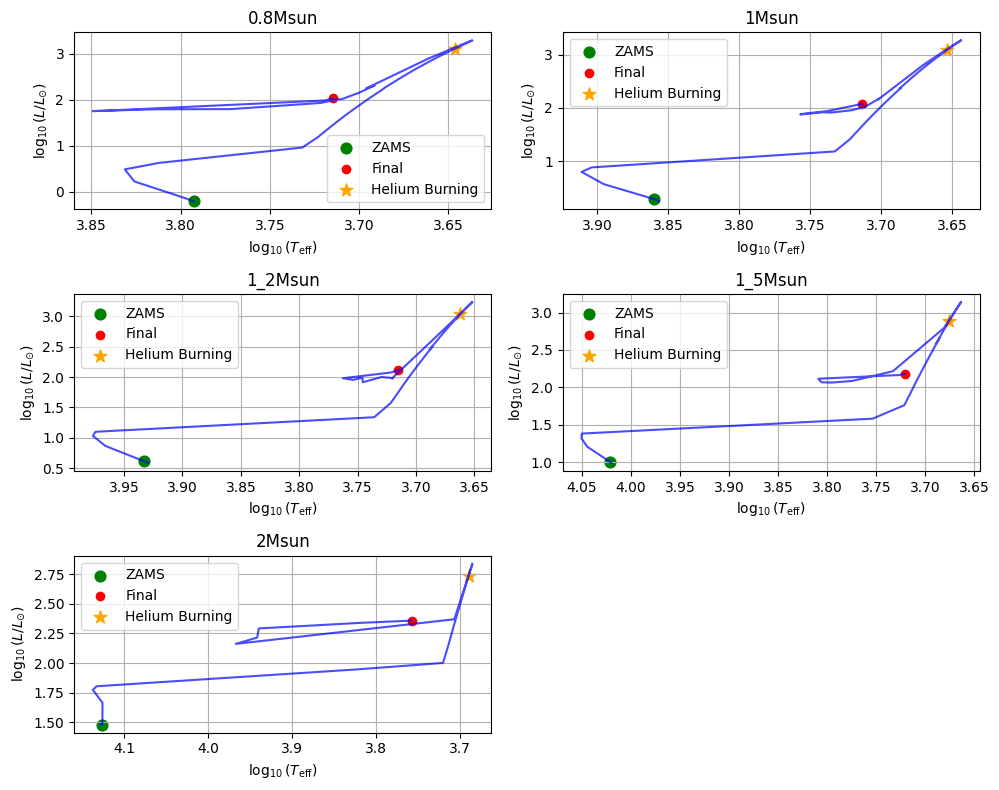

In [7]:
fig, ax = plt.subplots(3, 2, figsize=(10, 8))

# Use only the last 5 tracks (skip 0.5 Msun)
for a, h, title, zi in zip(ax.flatten(), H[0:], Ti[0:], zams_idxs[0:]):

    idx = np.argsort(h.star_age)
    Teff = h.log_Teff[idx]
    L = h.log_L[idx]

    mask = np.isfinite(Teff) & np.isfinite(L)
    Teff, L = Teff[mask], L[mask]

    a.plot(Teff, L, color="blue", alpha=0.7)

    a.scatter(h.log_Teff[zi], h.log_L[zi],
              color='green', s=60, label='ZAMS')

    a.scatter(h.log_Teff[-1], h.log_L[-1],
              color='red', label='Final')

    # He burning onset: first model with log_LHe > -2 (guarded, no silent argmax)
    He_found = np.where(h.log_LHe > -2)[0]
    if len(He_found) > 0:
        He_start_idx = He_found[0]
        a.scatter(h.log_Teff[He_start_idx], h.log_L[He_start_idx],
                  marker='*', s=90, color='orange', label='Helium Burning')

    a.invert_xaxis()
    a.grid()
    a.legend()
    a.set_xlabel(r"$\log_{10}(T_{\rm eff})$")
    a.set_ylabel(r"$\log_{10}(L/L_{\odot})$")
    a.set_title(title)

# Hide sixth panel
ax[2, 1].axis('off')

plt.tight_layout()
plt.show()

# LUMINOSITY vs AGE

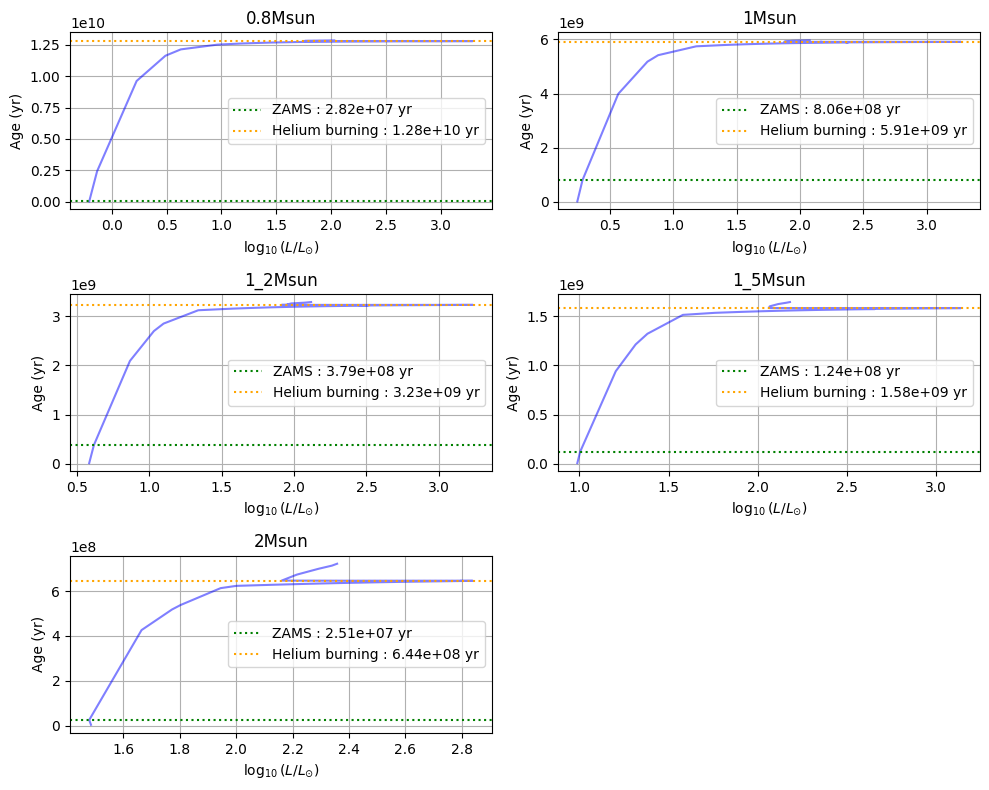

In [8]:
fig, ax = plt.subplots(3, 2, figsize=(10, 8))

for a, h, title, zi in zip(ax.flatten(), H[0:], Ti[0:], zams_idxs[0:]):  

    a.plot(h.log_L, h.star_age, color="blue", alpha=0.5)

    ZAMS_age = h.star_age[zi]
    a.axhline(
        ZAMS_age,
        linestyle='dotted',
        color="green",
        label=f"ZAMS : {ZAMS_age:.2e} yr"
    )

    He_found = np.where(h.log_LHe > -2)[0]
    if len(He_found) > 0:
        He_age = h.star_age[He_found[0]]
        a.axhline(
            He_age,
            linestyle='dotted',
            color="orange",
            label=f"Helium burning : {He_age:.2e} yr"
        )

    a.grid()
    a.legend()
    a.set_ylabel("Age (yr)")
    a.set_xlabel(r"$\log_{10}(L/L_{\odot})$")
    a.set_title(title)

# Hide empty sixth panel
ax[2, 1].axis('off')

plt.tight_layout()
plt.show()

# ZAMS TABLE

In [9]:
zams_rows = []

for h, name, zi in zip(H, Ti, zams_idxs):

    row = {col: getattr(h, col)[zi] for col in h.bulk_names}
    row['track'] = name

    # independent check: age when central H has dropped by 0.0015 from its ZAMS value
    j = np.where(h.center_h1 <= h.center_h1[zi] - 0.0015)[0]
    row['age_Xc_drop'] = h.star_age[j[0]] if len(j) > 0 else np.nan

    zams_rows.append(row)

low_zams_table = pd.DataFrame(zams_rows)
low_zams_table = low_zams_table.sort_values(['star_mass'], ascending=True)
low_zams_table.to_csv('low_zams_table.csv', index=False)

show = ['track', 'star_mass', 'model_number', 'star_age', 'age_Xc_drop',
        'log_Teff', 'log_L', 'log_R', 'log_g']
print(low_zams_table[show].to_string(index=False, float_format=lambda x: f"{x:.4g}"))

# ZAMS age should fall as mass rises
print("ZAMS age decreases with mass:", np.all(np.diff(low_zams_table.star_age) < 0))

  track  star_mass  model_number  star_age  age_Xc_drop  log_Teff   log_L    log_R  log_g
0.8Msun        0.8           168 2.819e+07    2.432e+09     3.792 -0.2069  -0.1657  4.673
  1Msun          1           200 8.057e+08     3.99e+09      3.86  0.2819 -0.05543  4.549
1_2Msun        1.2           200 3.792e+08    2.092e+09     3.933  0.6174 -0.03536  4.588
1_5Msun        1.5           200 1.235e+08    9.416e+08     4.021   1.004 -0.01775   4.65
  2Msun          2           200 2.505e+07     4.26e+08     4.126   1.479   0.0103  4.719
ZAMS age decreases with mass: False


# MASS-LUMINOSITY RELATION

In [10]:
logM = np.log10(low_zams_table.star_mass.to_numpy())
logl = low_zams_table.log_L.to_numpy()

LML = linregress(logM, logl)

print("Slope =", LML.slope)
print("Intercept =", LML.intercept)
print("R² =", LML.rvalue**2)
print("Slope error =", LML.stderr)
print("Intercept error =", LML.intercept_stderr)

Slope = 4.199461071787263
Intercept = 0.24935899866825317
R² = 0.9963424646550498
Slope error = 0.14690036604754253
Intercept error = 0.024341919042146217


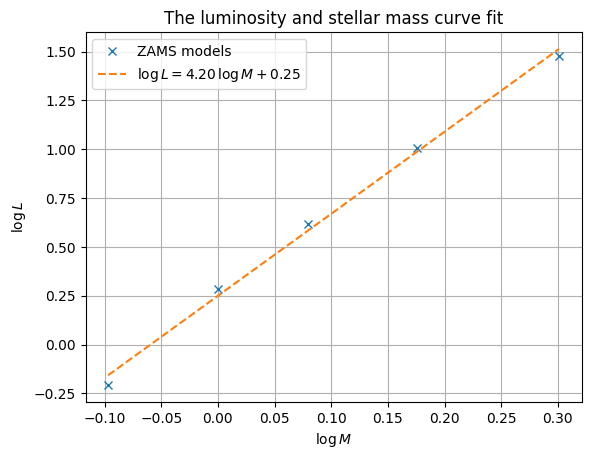

residuals (dex): [-0.0493  0.0326  0.0355  0.0154 -0.0342]


In [11]:
xfit = np.linspace(logM.min(), logM.max(), 50)

plt.plot(logM, logl, marker='x', linestyle='None', label="ZAMS models")
plt.plot(xfit, LML.slope*xfit + LML.intercept, linestyle='--',
         label=f"$\\log L = {LML.slope:.2f}\\,\\log M + {LML.intercept:.2f}$")
plt.xlabel("$\\log M$")
plt.ylabel("$\\log L$")
plt.title("The luminosity and stellar mass curve fit")
plt.legend()
plt.grid()
plt.show()

# residuals: a systematic pattern means a single power law is not a perfect description
resid = logl - (LML.slope*logM + LML.intercept)
print("residuals (dex):", np.round(resid, 4))

# STEFAN-BOLTZMANN CONSISTENCY CHECK

In [12]:
logr = low_zams_table.log_R.to_numpy()
logT = low_zams_table.log_Teff.to_numpy()

x = np.column_stack([np.ones(len(logl)), logT, logr])
coff, *_ = np.linalg.lstsq(x, logl, rcond=None)
a, b, c = coff

print("intercept              a =", a)
print("coefficient of logTeff b =", b, "(expected 4)")
print("coefficient of logR    c =", c, "(expected 2)")

# the intercept is just the solar normalisation, -4*log10(Teff_sun)
print("-4*log10(5772)  =", -4*np.log10(5772))

intercept              a = -15.04530632172906
coefficient of logTeff b = 4.000000000000085 (expected 4)
coefficient of logR    c = 1.9999999999999478 (expected 2)
-4*log10(5772)  = -15.045305289685826
